# BlackLegend — Análisis exploratorio de datos
**Modelos y Simulación de Sistemas II — Universidad de Antioquia**
Bryan David Molina · David Julian Penagos · Xiomara Giraldo Pérez

**Problema:** predecir si un solicitante pagará su préstamo en su totalidad (`loan_paid_back`) a partir de su información demográfica, financiera y crediticia y de las condiciones del préstamo. Es un problema de **aprendizaje supervisado de clasificación binaria**.

Este notebook reproduce la Sección I del reporte: la Tabla I (diccionario de variables) y las Figuras 1 a 4.

**Cambios frente a la versión del Entregable I**:
1. Se agrega la tabla con todas las variables: tipo, unidad, rango y significado (Tabla I).
2. Se agregan gráficas: distribuciones por clase, mapa de correlaciones y relación entre `credit_score` y el grado.
3. Se corrige la interpretación de `grade_subgrade`, `interest_rate` e `installment`: además de ser condiciones fijadas por la entidad, son **redundantes** (se demuestra en la sección 7), por lo que el "escenario B" no es una cota superior del desempeño.
4. Se documenta la colinealidad entre `delinquency_history` y `num_of_delinquencies` (r = 0,90) y entre `annual_income` y `total_credit_limit` (r = 0,89).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

os.makedirs('figs', exist_ok=True); os.makedirs('resultados', exist_ok=True)
PAGO, INCUMPLE, GRIS = '#2a78d6', '#eb6834', '#52514e'   # azul = pagó (1), naranja = incumplió (0)
DIVERGENTE = LinearSegmentedColormap.from_list('div', [INCUMPLE, '#f0efec', PAGO])   # dos polos y punto medio neutro

ESTILO = {'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'font.size': 7.5, 'axes.spines.top': False,
          'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 8,
          'legend.fontsize': 6.5, 'legend.frameon': False}
ANCHO1, ANCHO2 = 3.4, 7.1   # ancho de una y dos columnas IEEE (pulgadas)
coma = lambda v, d=1: f'{v:.{d}f}'.replace('.', ',')
miles = lambda v: f'{int(round(v)):,}'.replace(',', '.')

## 1. Carga y vista general

In [2]:
df = pd.read_csv('loan_dataset_20000.csv')
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (20000, 22)


,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [3]:
numericas_todas = df.drop(columns='loan_paid_back').select_dtypes('number').columns.tolist()
categoricas = df.select_dtypes(exclude='number').columns.tolist()
print(f'{len(numericas_todas)} predictoras numéricas y {len(categoricas)} categóricas')

15 predictoras numéricas y 6 categóricas


## 2. Diccionario de variables (Tabla I del reporte)

Tipo, unidad, rango observado y significado de las 22 columnas. El significado se toma de la descripción del conjunto de datos en Kaggle y de la convención de los datos de Lending Club, en los que se inspira.

In [4]:
significado = {
    'age': ('Demografía', 'Entera', 'años', 'Edad del solicitante'),
    'gender': ('Demografía', 'Nominal', '—', 'Género'),
    'marital_status': ('Demografía', 'Nominal', '—', 'Estado civil'),
    'education_level': ('Demografía', 'Nominal', '—', 'Máximo nivel educativo'),
    'annual_income': ('Financiera', 'Continua', 'USD/año', 'Ingreso anual'),
    'monthly_income': ('Financiera', 'Continua', 'USD/mes', 'Ingreso mensual (= ingreso anual / 12)'),
    'employment_status': ('Financiera', 'Nominal', '—', 'Situación laboral'),
    'debt_to_income_ratio': ('Financiera', 'Continua', 'razón', 'Deuda total dividida por el ingreso'),
    'credit_score': ('Financiera', 'Entera', 'puntos', 'Puntaje de crédito (tipo FICO)'),
    'loan_amount': ('Préstamo', 'Continua', 'USD', 'Monto solicitado'),
    'loan_purpose': ('Préstamo', 'Nominal', '—', 'Destino del préstamo'),
    'interest_rate': ('Préstamo', 'Continua', '% anual', 'Tasa de interés asignada'),
    'loan_term': ('Préstamo', 'Binaria', 'meses', 'Plazo del préstamo'),
    'installment': ('Préstamo', 'Continua', 'USD/mes', 'Cuota mensual'),
    'grade_subgrade': ('Préstamo', 'Ordinal', '—', 'Calificación de riesgo asignada por la entidad'),
    'num_of_open_accounts': ('Historial', 'Entera', 'cuentas', 'Cuentas de crédito abiertas'),
    'total_credit_limit': ('Historial', 'Continua', 'USD', 'Cupo total de crédito'),
    'current_balance': ('Historial', 'Continua', 'USD', 'Saldo adeudado actual'),
    'delinquency_history': ('Historial', 'Entera', 'eventos', 'Moras registradas en el historial'),
    'public_records': ('Historial', 'Entera', 'registros', 'Registros públicos negativos (p. ej., quiebras)'),
    'num_of_delinquencies': ('Historial', 'Entera', 'eventos', 'Número total de moras'),
    'loan_paid_back': ('Objetivo', 'Binaria', '—', '1 = préstamo pagado; 0 = incumplimiento'),
}

def rango(c):
    s = df[c]
    if not pd.api.types.is_numeric_dtype(s):
        return f'{s.nunique()} categorías' if s.nunique() > 5 else ', '.join(sorted(s.unique()))
    if s.nunique() <= 3:
        return ', '.join(str(v) for v in sorted(s.unique()))
    if s.max() > 1000:
        return f'{miles(s.min())} – {miles(s.max())}'
    d = 0 if s.dtype.kind == 'i' else 2
    return f'{coma(s.min(), d)} – {coma(s.max(), d)}'

diccionario = pd.DataFrame([{'Variable': c, 'Grupo': significado[c][0], 'Tipo': significado[c][1], 'Unidad': significado[c][2],
                             'Rango o categorías': rango(c), 'Significado': significado[c][3],
                             'Faltantes': int(df[c].isna().sum())} for c in df.columns])
diccionario.to_csv('resultados/tabla_variables.csv', index=False)
diccionario

,Variable,Grupo,Tipo,Unidad,Rango o categorías,Significado,Faltantes
0,age,Demografía,Entera,años,21 – 75,Edad del solicitante,0
1,gender,Demografía,Nominal,—,"Female, Male, Other",Género,0
2,marital_status,Demografía,Nominal,—,"Divorced, Married, Single, Widowed",Estado civil,0
3,education_level,Demografía,Nominal,—,"Bachelor's, High School, Master's, Other, PhD",Máximo nivel educativo,0
4,annual_income,Financiera,Continua,USD/año,6.000 – 400.000,Ingreso anual,0
5,monthly_income,Financiera,Continua,USD/mes,500 – 33.333,Ingreso mensual (= ingreso anual / 12),0
6,employment_status,Financiera,Nominal,—,"Employed, Retired, Self-employed, Student, Une...",Situación laboral,0
7,debt_to_income_ratio,Financiera,Continua,razón,"0,01 – 0,67",Deuda total dividida por el ingreso,0
8,credit_score,Financiera,Entera,puntos,373 – 850,Puntaje de crédito (tipo FICO),0
9,loan_amount,Préstamo,Continua,USD,500 – 49.040,Monto solicitado,0


## 3. Calidad de los datos: faltantes, duplicados y redundancias

In [5]:
print('Valores faltantes:', df.isna().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())
dif = (df['annual_income'] / 12 - df['monthly_income']).abs()
print(f'Diferencia máxima |annual_income/12 - monthly_income| = {dif.max():.3f}')
print(f"Correlación annual_income vs monthly_income = {df['annual_income'].corr(df['monthly_income']):.4f}")

Valores faltantes: 0
Filas duplicadas: 0
Diferencia máxima |annual_income/12 - monthly_income| = 0.005
Correlación annual_income vs monthly_income = 1.0000


No hay faltantes ni duplicados, así que no se necesita imputación. `monthly_income` es `annual_income / 12` (la diferencia solo se debe al redondeo), por lo que se elimina.

## 4. Variable objetivo y variables categóricas (Fig. 1)

In [6]:
conteo = df['loan_paid_back'].value_counts().sort_index()
prop = conteo / conteo.sum()
display(pd.DataFrame({'n': conteo, 'proporción': prop.round(4)}).rename(index={0: '0 = incumplió', 1: '1 = pagó'}))

cat_cols = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']
for c in cat_cols:
    t = df.groupby(c)['loan_paid_back'].agg(n='size', tasa_pago='mean').sort_values('tasa_pago')
    print(f'--- {c} ({df[c].nunique()} categorías)'); print(t.round(3), end='\n\n')

,n,proporción
loan_paid_back,,
0 = incumplió,4002,0.2001
1 = pagó,15998,0.7999


--- gender (3 categorías)
            n  tasa_pago
gender                  
Other     430      0.793
Male     9536      0.798
Female  10034      0.802

--- marital_status (4 categorías)
                   n  tasa_pago
marital_status                 
Widowed          567      0.785
Single          9031      0.800
Married         8974      0.800
Divorced        1428      0.805

--- education_level (5 categorías)
                    n  tasa_pago
education_level                 
Bachelor's       8045      0.791
Master's         3724      0.798
Other            1508      0.804
High School      5919      0.808
PhD               804      0.828

--- employment_status (5 categorías)
                       n  tasa_pago
employment_status                  
Unemployed          2113      0.182
Student              781      0.407
Self-employed       2923      0.886
Employed           13007      0.887
Retired             1176      0.995

--- loan_purpose (8 categorías)
                       n  tasa_p

Las categorías de grade_subgrade son exactamente A1..F5: True


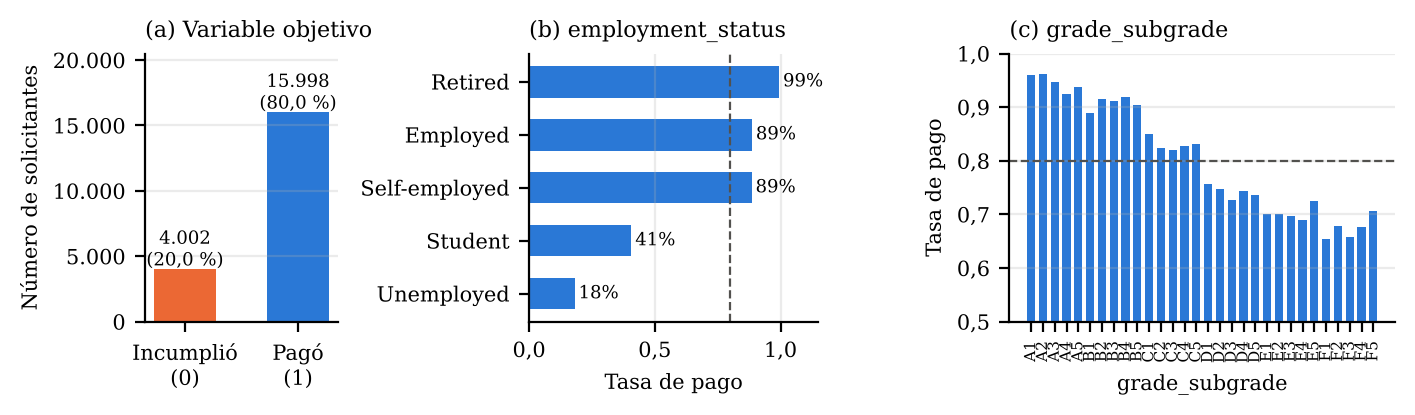

In [7]:
orden_grade = [f'{g}{i}' for g in 'ABCDEF' for i in range(1, 6)]
print('Las categorías de grade_subgrade son exactamente A1..F5:', sorted(df['grade_subgrade'].unique()) == orden_grade)
tasa_global = df['loan_paid_back'].mean()
tasa_grade = df.groupby('grade_subgrade')['loan_paid_back'].mean().reindex(orden_grade)

with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 3, figsize=(ANCHO2, 2.1), gridspec_kw={'width_ratios': [0.8, 1.2, 1.6]})
    ax = axes[0]
    barras = ax.bar(['Incumplió\n(0)', 'Pagó\n(1)'], conteo.values, color=[INCUMPLE, PAGO], width=0.55)
    for b, p in zip(barras, prop):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 300, f'{miles(b.get_height())}\n({coma(p * 100)} %)', ha='center', fontsize=6.5)
    ax.set_ylim(0, 20500); ax.set_ylabel('Número de solicitantes'); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: miles(v)))
    ax.set_title('(a) Variable objetivo', loc='left')

    ax = axes[1]
    t = df.groupby('employment_status')['loan_paid_back'].mean().sort_values()
    ax.barh(t.index, t.values, color=PAGO, height=0.6); ax.axvline(tasa_global, color=GRIS, ls='--', lw=0.8)
    for i, v in enumerate(t.values): ax.text(v + 0.015, i, f'{v:.0%}', va='center', fontsize=6.5)
    ax.set_xlim(0, 1.15); ax.set_xlabel('Tasa de pago'); ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: coma(v)))
    ax.set_title('(b) employment_status', loc='left')

    ax = axes[2]
    ax.bar(orden_grade, tasa_grade.values, color=PAGO, width=0.7); ax.axhline(tasa_global, color=GRIS, ls='--', lw=0.8)
    ax.set_ylim(0.5, 1); ax.set_ylabel('Tasa de pago'); ax.set_xlabel('grade_subgrade')
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: coma(v)))
    ax.tick_params(axis='x', rotation=90, labelsize=5.5); ax.grid(axis='x', visible=False)
    ax.set_title('(c) grade_subgrade', loc='left')
    fig.tight_layout(); fig.savefig('figs/fig1_objetivo_categoricas.png', dpi=300, bbox_inches='tight'); plt.show()

- **Desbalance 80/20:** un clasificador que siempre prediga "pagó" tendría 80 % de *accuracy* sin aprender nada; hacen falta métricas que tengan en cuenta la clase minoritaria.
- `employment_status` es la variable que más separa: pagaron el 18 % de los desempleados y el 41 % de los estudiantes, frente al 89 % de empleados e independientes y casi el 100 % de los jubilados.
- En `gender`, `marital_status`, `education_level` y `loan_purpose` las tasas de pago son casi iguales entre categorías (78 %–83 %).

## 5. Variables numéricas: estadísticos y distribuciones por clase (Fig. 2)

In [8]:
num_cols = ['age', 'annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate', 'loan_term',
            'installment', 'num_of_open_accounts', 'total_credit_limit', 'current_balance', 'delinquency_history',
            'public_records', 'num_of_delinquencies']
desc = df[num_cols].describe().T
desc['asimetría'] = df[num_cols].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
age,20000.0,48.03,15.83,21.00,35.00,48.00,62.00,75.00,0.01
annual_income,20000.0,43549.64,28668.58,6000.00,24260.75,36585.26,54677.92,400000.00,2.33
debt_to_income_ratio,20000.0,0.18,0.11,0.01,0.10,0.16,0.24,0.67,0.79
credit_score,20000.0,679.26,69.64,373.00,632.00,680.00,727.00,850.00,-0.07
loan_amount,20000.0,15129.30,8605.41,500.00,8852.70,14946.17,20998.87,49039.69,0.25
interest_rate,20000.0,12.40,2.44,3.14,10.74,12.40,14.00,22.51,0.03
loan_term,20000.0,43.22,11.01,36.00,36.00,36.00,60.00,60.00,0.87
installment,20000.0,455.63,274.62,9.43,253.91,435.60,633.60,1685.40,0.47
num_of_open_accounts,20000.0,5.01,2.24,0.00,3.00,5.00,6.00,15.00,0.45
total_credit_limit,20000.0,48649.82,32423.38,6157.80,27180.49,40241.62,60361.26,454394.19,2.49


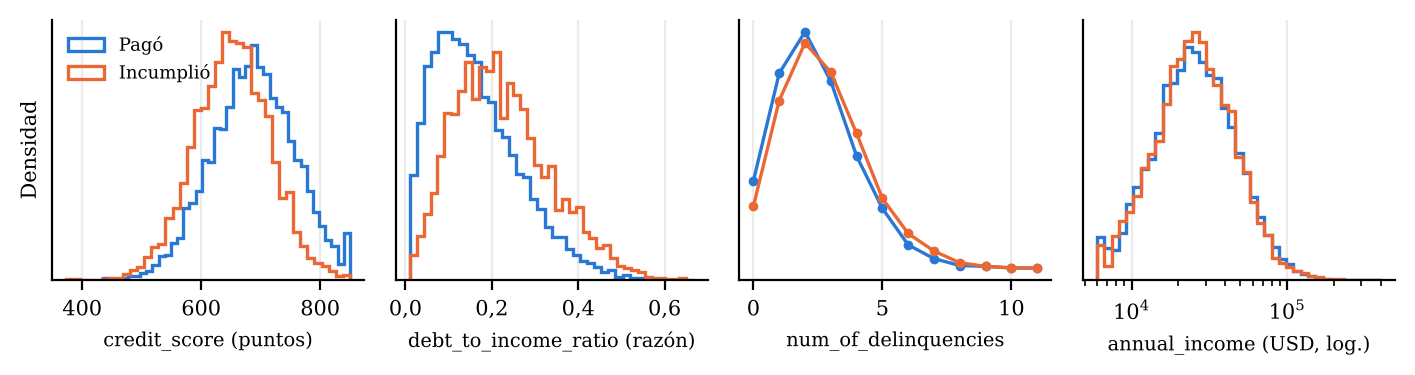

In [9]:
paneles = [('credit_score', 'credit_score (puntos)', False), ('debt_to_income_ratio', 'debt_to_income_ratio (razón)', False),
           ('num_of_delinquencies', 'num_of_delinquencies', True), ('annual_income', 'annual_income (USD, log.)', False)]
with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 4, figsize=(ANCHO2, 1.9))
    for ax, (c, etiqueta, discreta) in zip(axes, paneles):
        for clase, nombre, color in [(1, 'Pagó', PAGO), (0, 'Incumplió', INCUMPLE)]:
            v = df.loc[df.loan_paid_back == clase, c]
            if discreta:
                f = v.value_counts(normalize=True).sort_index()
                ax.plot(f.index, f.values, '-o', ms=2.5, lw=1.2, color=color, label=nombre)
            else:
                bins = np.logspace(np.log10(df[c].min()), np.log10(df[c].max()), 40) if c == 'annual_income' else 40
                ax.hist(v, bins=bins, density=True, histtype='step', lw=1.2, color=color, label=nombre)
        if c == 'annual_income': ax.set_xscale('log')
        ax.set_xlabel(etiqueta, fontsize=7); ax.set_yticks([])
        if c == 'debt_to_income_ratio': ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: coma(v)))
    axes[0].set_ylabel('Densidad'); axes[0].legend(loc='upper left')
    fig.tight_layout(); fig.savefig('figs/fig2_distribuciones.png', dpi=300, bbox_inches='tight'); plt.show()

Quienes incumplen tienen menor `credit_score`, mayor `debt_to_income_ratio` y más moras, pero las distribuciones se solapan mucho: ninguna variable numérica separa las clases por sí sola. En `annual_income` las dos curvas coinciden (no discrimina). Las variables monetarias tienen asimetría positiva fuerte (2,3 a 2,8).

## 6. Correlaciones (Fig. 3)

,debt_to_income_ratio,interest_rate,delinquency_history,num_of_delinquencies,installment,current_balance,total_credit_limit,loan_term,loan_amount,num_of_open_accounts,annual_income,public_records,age,credit_score
r con loan_paid_back,-0.224,-0.111,-0.085,-0.071,-0.01,-0.005,-0.003,-0.003,-0.002,0.003,0.003,0.003,0.008,0.2


Pares con |r| > 0,5:
annual_income        total_credit_limit      0.89
                     current_balance         0.65
credit_score         interest_rate          -0.57
loan_amount          installment             0.94
total_credit_limit   current_balance         0.73
delinquency_history  num_of_delinquencies    0.90


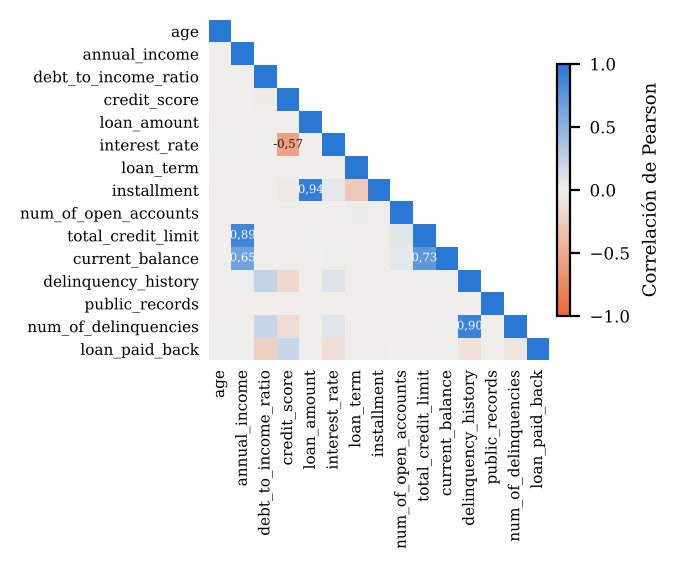

In [10]:
corr_t = df[num_cols + ['loan_paid_back']].corr()['loan_paid_back'].drop('loan_paid_back').sort_values()
display(corr_t.round(3).to_frame('r con loan_paid_back').T)

m = df[num_cols + ['loan_paid_back']].corr()
pares = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1)).stack()
print('Pares con |r| > 0,5:'); print(pares[pares.abs() > 0.5].round(2).to_string())

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(ANCHO1, 3.15))
    mm = m.where(np.tril(np.ones(m.shape, dtype=bool)))
    im = ax.imshow(mm, cmap=DIVERGENTE, vmin=-1, vmax=1)
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=90, fontsize=5.5)
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index, fontsize=5.5)
    for i in range(len(m)):
        for j in range(i):
            if abs(m.iloc[i, j]) >= 0.5:
                ax.text(j, i, coma(m.iloc[i, j], 2), ha='center', va='center', fontsize=4.2,
                        color='white' if abs(m.iloc[i, j]) > 0.6 else '#1a1a19')
    ax.grid(False); ax.spines[['left', 'bottom']].set_visible(False); ax.tick_params(length=0)
    cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02); cb.set_label('Correlación de Pearson', fontsize=6.5); cb.ax.tick_params(labelsize=6)
    fig.tight_layout(); fig.savefig('figs/fig3_correlaciones.png', dpi=300, bbox_inches='tight'); plt.show()

- Con la variable objetivo, las correlaciones lineales más altas son las de `debt_to_income_ratio` (−0,22), `credit_score` (0,20) e `interest_rate` (−0,11); las demás están cerca de cero.
- Entre predictoras hay tres bloques colineales: `loan_amount`–`installment` (0,94), `delinquency_history`–`num_of_delinquencies` (0,90) y `annual_income`–`total_credit_limit`–`current_balance` (0,65 a 0,89). `credit_score` e `interest_rate` tienen r = −0,57.

## 7. `grade_subgrade`, `interest_rate` e `installment`: variables redundantes (Fig. 4)

En el Entregable I se trataron como posible *fuga de información*. La revisión muestra algo más preciso:
- La **letra del grado** es una discretización exacta de `credit_score` (los rangos no se solapan).
- El **subgrado** (1 a 5) no tiene relación con `credit_score` dentro de cada letra.
- `installment` es la **fórmula de amortización** aplicada a `loan_amount`, `interest_rate` y `loan_term`.

grade_subgrade,A,B,C,D,E,F
min,800,740,670,610,580,373
max,850,799,739,669,609,579
count,869,3075,7245,5565,1695,1551


Correlación subgrado vs credit_score dentro de cada letra: {'A': np.float64(-0.012), 'B': np.float64(0.044), 'C': np.float64(-0.008), 'D': np.float64(0.006), 'E': np.float64(0.001), 'F': np.float64(0.03)}
Diferencia máxima entre installment y la fórmula de amortización: 0.005 USD
Correlación de Spearman entre grade_subgrade (ordinal) e interest_rate: 0.51


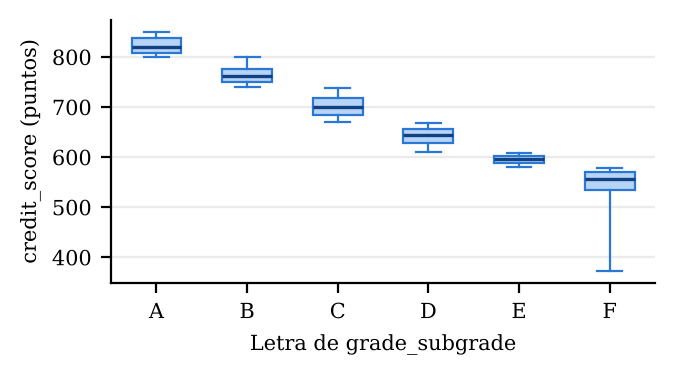

In [11]:
letra = df['grade_subgrade'].str[0]; sub = df['grade_subgrade'].str[1].astype(int)
rangos = df.groupby(letra)['credit_score'].agg(['min', 'max', 'count'])
display(rangos.T)
print('Correlación subgrado vs credit_score dentro de cada letra:',
      {g: round(sub[letra == g].corr(df.loc[letra == g, 'credit_score']), 3) for g in 'ABCDEF'})

r, n = df['interest_rate'] / 1200, df['loan_term']
cuota = df['loan_amount'] * r / (1 - (1 + r) ** -n)
print(f"Diferencia máxima entre installment y la fórmula de amortización: {(cuota - df['installment']).abs().max():.3f} USD")
rho = df['grade_subgrade'].map({k: i for i, k in enumerate(orden_grade)}).corr(df['interest_rate'], method='spearman')
print(f'Correlación de Spearman entre grade_subgrade (ordinal) e interest_rate: {rho:.2f}')

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(ANCHO1, 1.9))
    datos = [df.loc[letra == g, 'credit_score'] for g in 'ABCDEF']
    bp = ax.boxplot(datos, tick_labels=list('ABCDEF'), widths=0.55, patch_artist=True, whis=(0, 100),
                    medianprops={'color': '#104281', 'lw': 1.2}, boxprops={'facecolor': '#b7d3f6', 'edgecolor': PAGO, 'lw': 0.8},
                    whiskerprops={'color': PAGO, 'lw': 0.8}, capprops={'color': PAGO, 'lw': 0.8})
    ax.set_xlabel('Letra de grade_subgrade'); ax.set_ylabel('credit_score (puntos)'); ax.grid(axis='x', visible=False)
    fig.tight_layout(); fig.savefig('figs/fig4_grade_credit_score.png', dpi=300, bbox_inches='tight'); plt.show()

**Decisión.** Las tres variables se excluyen del modelo principal por dos razones: (i) son condiciones que la entidad fija después de evaluar al solicitante, así que no estarían disponibles si el sistema se usa para decidir la aprobación, y (ii) no aportan información nueva. Se plantean dos escenarios:
- **Escenario A (principal):** sin `grade_subgrade`, `interest_rate` ni `installment`.
- **Escenario B (referencia):** con todas las variables, para comprobar empíricamente que no se pierde desempeño (ver `02_Modelos_BlackLegend.ipynb`).

## 8. Codificación

In [12]:
nominales = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']
redundantes = ['grade_subgrade', 'interest_rate', 'installment']
descartar = ['monthly_income', 'loan_paid_back']
numericas_A = [c for c in df.columns if c not in nominales + redundantes + descartar]

# Solo se cuenta cuántas columnas genera la codificación; el ajuste real se hace dentro de la validación cruzada.
codificador_A = ColumnTransformer([('num', StandardScaler(), numericas_A),
                                   ('cat', OneHotEncoder(handle_unknown='ignore'), nominales)])
n_vars = codificador_A.fit(df[numericas_A + nominales]).transform(df[numericas_A + nominales].head(1)).shape[1]
print(f'{len(numericas_A)} numéricas + {sum(df[c].nunique() for c in nominales)} columnas One-Hot = {n_vars} variables de entrada (escenario A)')
print('Registros con education_level = "Other":', (df['education_level'] == 'Other').sum())

12 numéricas + 25 columnas One-Hot = 37 variables de entrada (escenario A)
Registros con education_level = "Other": 1508


- **One-Hot Encoding** para las cinco variables nominales (3 a 8 categorías). `education_level` tiene un orden parcial, pero la categoría "Other" (1.508 registros) no se puede ubicar en la escala.
- **Ordinal Encoding** para `grade_subgrade` (A1 = 0, …, F5 = 29), solo en el escenario B.
- **Estandarización** de las variables numéricas dentro del `Pipeline`, ajustada solo con los datos de entrenamiento de cada pliegue.

## 9. Resumen de hallazgos
1. 20.000 registros y 22 columnas (21 predictoras y la variable objetivo), sin faltantes ni duplicados.
2. Desbalance de 80/20: *accuracy* no es suficiente.
3. `monthly_income` es redundante (`annual_income`/12) y se elimina.
4. `grade_subgrade` (letra) es una discretización de `credit_score` e `installment` es función de monto, tasa y plazo.
5. Las variables más relacionadas con el pago son `employment_status`, `debt_to_income_ratio`, `credit_score` y el historial de moras.
6. Hay tres bloques de variables colineales, candidatos a reducción de dimensión.